In [1]:
from src.benchmark import benchmark
import matplotlib.pyplot as plt
from pathlib import Path
from statistics import mean
from src.keypad.keypad import (
    SlidingTowerShuffleKeypad,
)


In [2]:
multiple = 1
number_of_keys = 6
properties_per_key = 8 * multiple
passcode_len = 4
max_tries_before_lockout = 5
complexity = 4
disparity = 4
run_count = 10000

bench_sliding_tower_shuffle = benchmark(
    number_of_keys=number_of_keys,
    properties_per_key=properties_per_key,
    passcode_len=passcode_len,
    max_tries_before_lockout=max_tries_before_lockout,
    run_count=run_count,
    complexity=complexity,
    disparity=disparity,
    keypad=SlidingTowerShuffleKeypad.new_keypad(number_of_keys, properties_per_key)
)


In [3]:
print(f"Bench Sliding Tower Shuffle Break {mean(bench_sliding_tower_shuffle.iterations_to_break)}\n")
print(f"Bench Sliding Tower Shuffle Replay {mean(bench_sliding_tower_shuffle.iterations_to_replay)}\n")


Bench Sliding Tower Shuffle Break 5

Bench Sliding Tower Shuffle Replay 5



In [4]:
def bench_histogram(data, title, number_of_keys, properties_per_key,
                    passcode_len, max_tries_before_lockout, complexity, disparity, run_count, save_path: Path = None):
    # Create the histogram
    min_val = min(data)
    max_val = max(data)

    # Create bins for each integer
    bins = range(min_val, max_val + 2)
    plt.hist(data, bins=bins, edgecolor='black')

    # Add titles and labels
    plt.title(title)
    plt.xlabel('# of Login Observations')
    plt.ylabel('Simulations')

    # Display parameters as text in the plot
    text = (f"number_of_keys={number_of_keys}\n"
            f"properties_per_key={properties_per_key}\n"
            f"passcode_len={passcode_len}\n"
            f"max_tries_before_lockout={max_tries_before_lockout}\n"
            f"complexity={complexity}\n"
            f"disparity={disparity}\n"
            f"run_count={run_count}")

    plt.text(0.95, 0.95, text, transform=plt.gca().transAxes, fontsize=10,
             verticalalignment='top', horizontalalignment='right', bbox=dict(facecolor='white', alpha=0.5))

    # Save plot if a path is provided
    if save_path:
        save_path.mkdir(parents=True, exist_ok=True)
        filename = (f"{title.replace(' ', '_')}_multi{multiple}_keys{number_of_keys}_"
                    f"props{properties_per_key}_pass{passcode_len}_tries{max_tries_before_lockout}_"
                    f"comp{complexity}_disp{disparity}_runs{run_count}.png")
        plt.savefig(save_path / filename, bbox_inches='tight', dpi=300)

    # Display the plot
    plt.show()


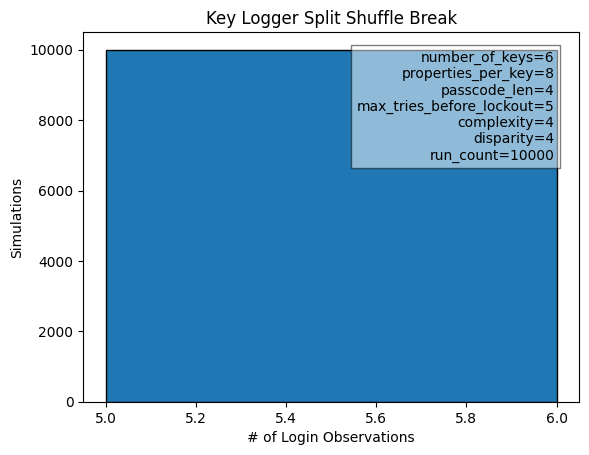

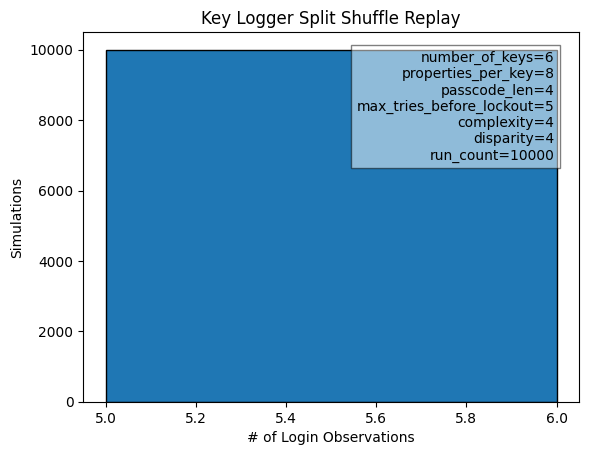

In [5]:
bench_histogram(bench_sliding_tower_shuffle.iterations_to_break, "Key Logger Split Shuffle Break", number_of_keys,
                properties_per_key,
                passcode_len, max_tries_before_lockout, complexity, disparity, run_count, Path("../output/histograms"))
bench_histogram(bench_sliding_tower_shuffle.iterations_to_replay, "Key Logger Split Shuffle Replay", number_of_keys,
                properties_per_key,
                passcode_len, max_tries_before_lockout, complexity, disparity, run_count, Path("../output/histograms"))
